# Marketing Campaign Performance and Sales Revenue Analysis

## 1. Project Overview

### 1.1 Business Problem

Businesses invest in multiple marketing channels to reach customers and generate sales revenue. However, higher advertising spending does not always correspond to stronger sales performance.

Understanding which marketing channels, customer segments, and product categories are associated with better outcomes can help businesses evaluate their marketing strategies and identify opportunities for improvement.

This project uses exploratory data analysis (EDA) to investigate marketing campaign performance, examine factors associated with sales revenue, and evaluate advertising efficiency.

### 1.2 Business Questions

The analysis aims to answer the following questions:

1. **Which marketing channels generate the highest sales revenue?**
2. **Which product categories and customer segments perform best?**
3. **How does sales revenue change over time, and are there seasonal patterns?**
4. **Which marketing factors are most strongly associated with sales revenue?**
5. **How do discount rates relate to sales revenue?**
6. **Which marketing channel and customer segment combinations demonstrate the strongest performance?**
7. **Which combinations generate the highest revenue relative to advertising spending?**
8. **How do extreme advertising spending values affect marketing efficiency results?**

### 1.3 Dataset Overview

The dataset contains **18,000 marketing campaign records and 17 original columns** covering advertising expenditure, customer segments, marketing channels, product categories, campaign characteristics, engagement metrics, and sales revenue.

### 1.4 Tools and Technologies

- **Python:** Data cleaning and exploratory analysis
- **Pandas and NumPy:** Data manipulation and calculations
- **Matplotlib and Seaborn:** Data visualization
- **Jupyter Notebook:** Analysis and documentation
- **Power BI:** Interactive dashboard development

### 1.5 Analytical Approach

The project follows these stages:

1. Data understanding and quality assessment
2. Data cleaning and preprocessing
3. Exploratory data analysis
4. Marketing channel and customer segment comparisons
5. Revenue-to-advertising-spend evaluation
6. Outlier sensitivity analysis
7. Business insights and recommendations

In [51]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## 2. Data Understanding and Initial Exploration

Before performing the analysis, the dataset is examined to understand its structure, data types, statistical characteristics, and overall quality.

This stage includes:
- Inspecting the dataset's dimensions and column names.
- Reviewing data types and sample records.
- Identifying missing values and duplicate records.
- Examining descriptive statistics and numerical distributions.

These checks help identify potential data quality issues that need to be addressed before further analysis.

In [52]:

df = pd.read_csv("marketing_campaign_data.csv", sep=";")

df.head()


,id,date,region,channel,product_category,customer_segment,ad_spend,price,discount_rate,market_reach,impressions,click_through_rate,competition_index,seasonality_index,campaign_duration_days,customer_lifetime_value,sales_revenue
0,1,05/12/2011 11:31,Nort,Search,General,Standard,9.00,0.75,0.2782,32.0,817,0.0010,3.34,1.000000,30.0,816.49,119.767811
1,2,27/04/2011 14:01,North,Social Media,General,Premium,3.35,3.35,0.0912,61.0,2289,0.0640,4.44,0.366025,90.0,1723.16,119.404661
2,3,09/11/2010 15:20,North,Affiliate,General,Budget,2.55,2.55,0.1997,461.0,14697,0.1508,3.31,0.366025,21.0,1151.74,132.009747
3,4,03/10/2010 15:24,North,Affiliate,Storage,Premium,2.95,2.95,0.4767,744.0,17578,0.1965,2.87,-0.366025,90.0,3585.85,154.511756
4,5,14/10/2011 09:28,North,Search,Lighting,Premium,15.00,1.25,0.3536,226.0,6280,0.0200,7.40,-0.366025,90.0,502.28,128.059924


In [53]:

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Number of rows: 18000
Number of columns: 17


In [54]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18000 entries, 0 to 17999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       18000 non-null  int64  
 1   date                     18000 non-null  object 
 2   region                   18000 non-null  object 
 3   channel                  18000 non-null  object 
 4   product_category         18000 non-null  object 
 5   customer_segment         18000 non-null  object 
 6   ad_spend                 17342 non-null  float64
 7   price                    18000 non-null  float64
 8   discount_rate            17245 non-null  float64
 9   market_reach             17314 non-null  float64
 10  impressions              18000 non-null  int64  
 11  click_through_rate       17287 non-null  float64
 12  competition_index        17293 non-null  float64
 13  seasonality_index        18000 non-null  float64
 14  campaign_duration_days

In [55]:

df.isnull().sum()


,0
id,0
date,0
region,0
channel,0
product_category,0
customer_segment,0
ad_spend,658
price,0
discount_rate,755
market_reach,686


In [56]:

print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 0


In [57]:

df.describe()


,id,ad_spend,price,discount_rate,market_reach,impressions,click_through_rate,competition_index,seasonality_index,campaign_duration_days,customer_lifetime_value,sales_revenue
count,18000.000000,17342.000000,18000.000000,17245.000000,17314.000000,18000.000000,17287.000000,17293.000000,18000.000000,16487.000000,17257.000000,18000.000000
mean,9000.500000,44.071797,5.648265,0.230045,321.393323,7257.423889,0.057141,4.004004,-0.014902,35.565597,10317.172008,137.204937
std,5196.296758,190.165450,22.456661,0.149955,244.853653,7600.666112,0.049452,1.994997,0.919343,27.039417,35581.519328,54.961808
min,1.000000,0.180000,0.040000,0.000200,1.000000,-30771.000000,0.000000,0.040000,-1.366025,7.000000,0.550000,0.000000
25%,4500.750000,4.950000,1.250000,0.109500,138.000000,2503.750000,0.020450,2.440000,-1.000000,14.000000,573.110000,100.088209
50%,9000.500000,11.900000,1.950000,0.204000,269.000000,5106.500000,0.043500,3.870000,0.366025,28.000000,1781.440000,129.113361
75%,13500.250000,19.800000,3.750000,0.324900,439.000000,9566.250000,0.079900,5.410000,1.000000,60.000000,5502.780000,164.688454
max,18000.000000,4254.500000,295.000000,0.600000,1490.000000,173986.000000,0.435700,9.650000,1.366025,90.000000,543228.100000,684.320270


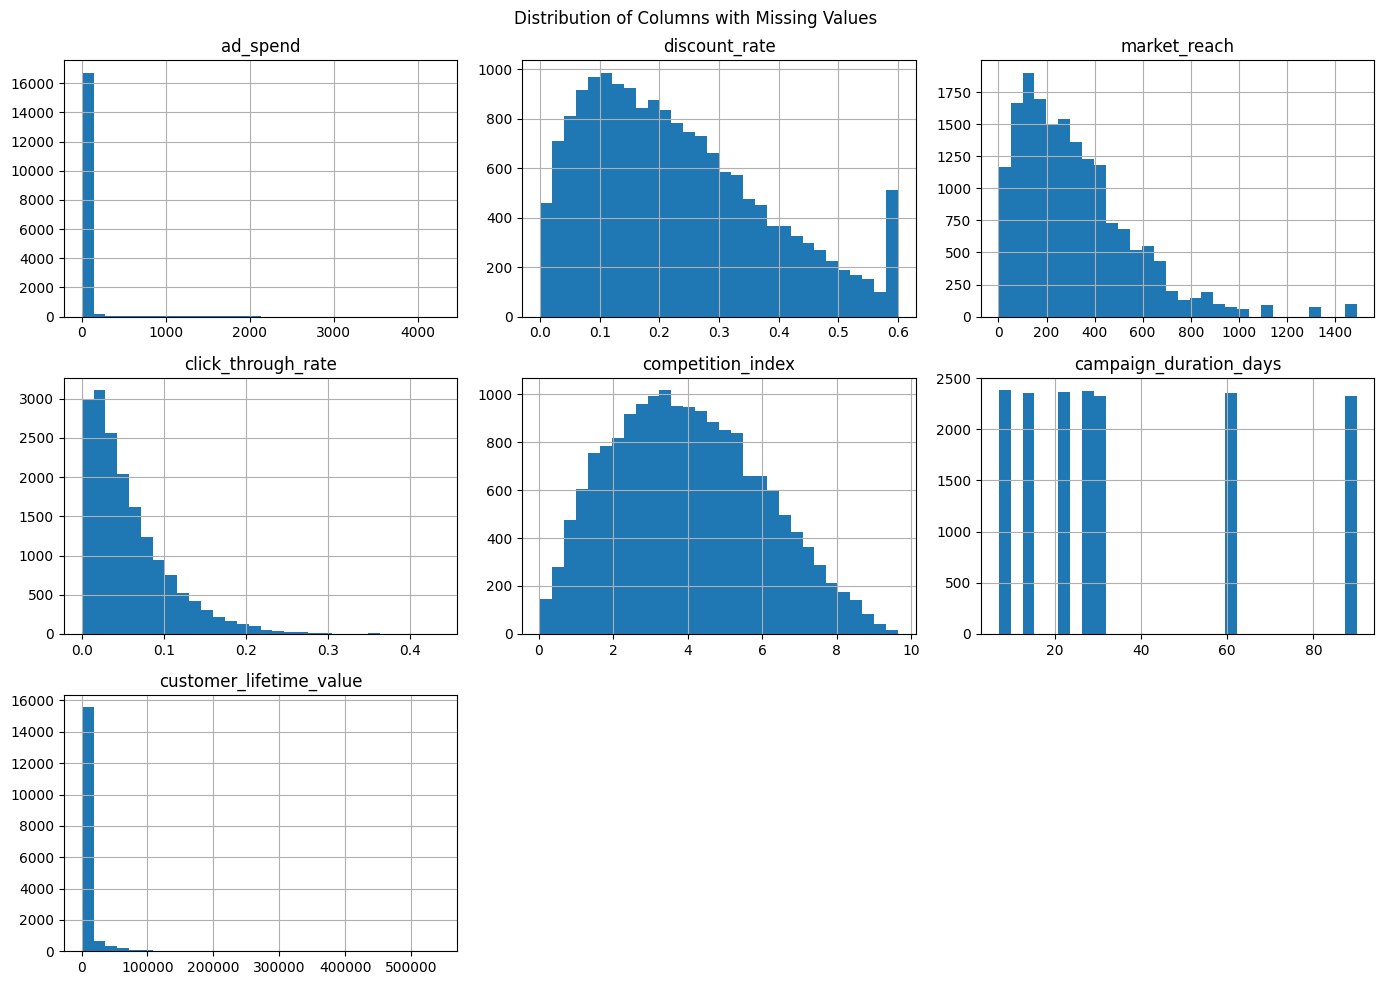

In [58]:

missing_cols = df.columns[df.isnull().sum() > 0]

df[missing_cols].hist(
    figsize=(14, 10),
    bins=30
)

plt.suptitle("Distribution of Columns with Missing Values")
plt.tight_layout()
plt.show()


## 3. Data Cleaning and Preprocessing

Data cleaning was performed to improve data quality and prepare the dataset for reliable analysis.

The following issues were addressed:

- **Missing values:** Numerical columns were imputed using appropriate statistical measures, including the median, mean, and mode.
- **Invalid impressions:** Negative impression values were treated as invalid and replaced using the median of valid impressions.
- **Outliers:** Extreme values in advertising spend, product price, and customer lifetime value were examined using the Interquartile Range (IQR) method. These values were retained because there was insufficient evidence that they represented errors.
- **Categorical inconsistencies:** Inconsistent spelling, capitalization, and formatting in region and marketing channel names were standardized.
- **Date formatting:** Mixed date formats were converted into a consistent datetime format. Year, month, and quarter features were extracted for time-based analysis.

The objective was to improve data consistency while preserving potentially meaningful information.

In [59]:

df_clean = df.copy()

median_cols = [
    'ad_spend',
    'discount_rate',
    'market_reach',
    'click_through_rate',
    'customer_lifetime_value'
]

for col in median_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

df_clean['competition_index'] = df_clean[
    'competition_index'
].fillna(df_clean['competition_index'].mean())

df_clean['campaign_duration_days'] = df_clean[
    'campaign_duration_days'
].fillna(df_clean['campaign_duration_days'].mode()[0])


In [60]:

print("Remaining missing values:")
print(df_clean.isnull().sum())

print("\nTotal missing values:", df_clean.isnull().sum().sum())


Remaining missing values:
id                         0
date                       0
region                     0
channel                    0
product_category           0
customer_segment           0
ad_spend                   0
price                      0
discount_rate              0
market_reach               0
impressions                0
click_through_rate         0
competition_index          0
seasonality_index          0
campaign_duration_days     0
customer_lifetime_value    0
sales_revenue              0
dtype: int64

Total missing values: 0


In [61]:

negative_impressions = df_clean[df_clean['impressions'] < 0]

print("Number of negative impressions:",
      len(negative_impressions))

display(negative_impressions.head(10))


Number of negative impressions: 77


,id,date,region,channel,product_category,customer_segment,ad_spend,price,discount_rate,market_reach,impressions,click_through_rate,competition_index,seasonality_index,campaign_duration_days,customer_lifetime_value,sales_revenue
79,80,08/08/2010 15:53,North,Email,General,Standard,11.90,1.250000,0.1123,35.0,-449,0.1320,6.510000,-1.366025,28.0,186.40,91.204990
284,285,01/07/2010 16:48,North,Influencer,Kitchen,Premium,3.75,1.250000,0.3000,56.0,-381,0.0282,5.210000,-1.366025,28.0,1781.44,85.345371
945,946,07/04/2011 12:04,North,Email,Lighting,Premium,47.20,2.950000,0.1330,234.0,-6072,0.0763,4.160000,0.366025,60.0,522.45,154.607969
1105,1106,06/12/2011 12:12,North,Search,Lighting,Premium,1.58,0.790000,0.2372,32.0,-403,0.0115,4.004004,1.000000,21.0,1341.65,113.718991
1255,1256,25/02/2010 15:13,North,Search,Kitchen,Premium,15.30,2.550000,0.3427,266.0,-9380,0.0166,2.990000,1.366025,30.0,643.32,132.069691
1352,1353,11/07/2011 12:49,North,TV,Storage,Standard,0.55,0.550000,0.3202,521.0,-7035,0.0186,4.240000,-1.366025,7.0,421.69,155.170183
1411,1412,15/07/2010 14:55,North,Social Media,General,Budget,2.50,150.317041,0.0563,90.0,-2350,0.0155,7.700000,-1.366025,90.0,38.25,49.111847
2148,2149,07/06/2011 13:44,North,Search,General,Standard,1.66,0.830000,0.1119,179.0,-7210,0.1041,2.070000,-1.000000,14.0,1008.11,179.718201
2470,2471,29/09/2010 11:19,North,Social Media,General,Premium,5.90,2.950000,0.0776,423.0,-13147,0.0549,2.590000,-1.000000,7.0,6188.36,127.726343
2638,2639,26/07/2010 13:35,North,Email,Stationery,Premium,20.16,180.238932,0.2044,77.0,-687,0.0180,5.290000,-1.366025,90.0,2382.68,21.634716


In [62]:

df_clean.loc[
    df_clean['impressions'] < 0,
    'impressions'
] = np.nan

print("Missing impressions:",
      df_clean['impressions'].isnull().sum())


Missing impressions: 77


In [63]:

df_clean['impressions'] = df_clean['impressions'].fillna(
    df_clean['impressions'].median()
)

print("Negative impressions:",
      (df_clean['impressions'] < 0).sum())

print("Missing impressions:",
      df_clean['impressions'].isnull().sum())


Negative impressions: 0
Missing impressions: 0


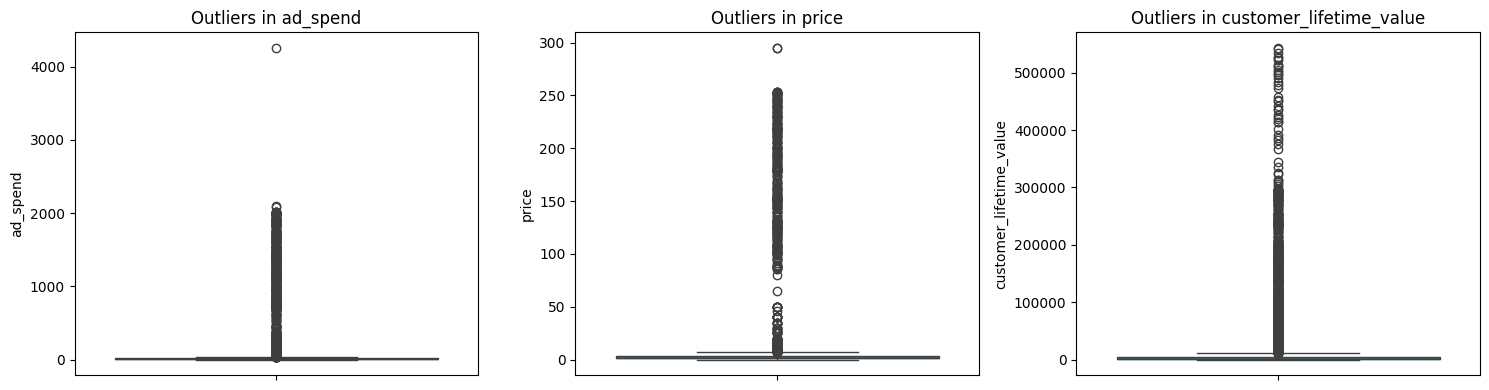

In [64]:

columns = ['ad_spend', 'price', 'customer_lifetime_value']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, col in enumerate(columns):
    sns.boxplot(y=df_clean[col], ax=axes[i])
    axes[i].set_title(f'Outliers in {col}')

plt.tight_layout()
plt.show()


In [65]:

columns = ['ad_spend', 'price', 'customer_lifetime_value']

for col in columns:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    ]

    print(f"{col}: {len(outliers)} outliers "
          f"({len(outliers) / len(df_clean) * 100:.2f}%)")


ad_spend: 1663 outliers (9.24%)
price: 1688 outliers (9.38%)
customer_lifetime_value: 2240 outliers (12.44%)


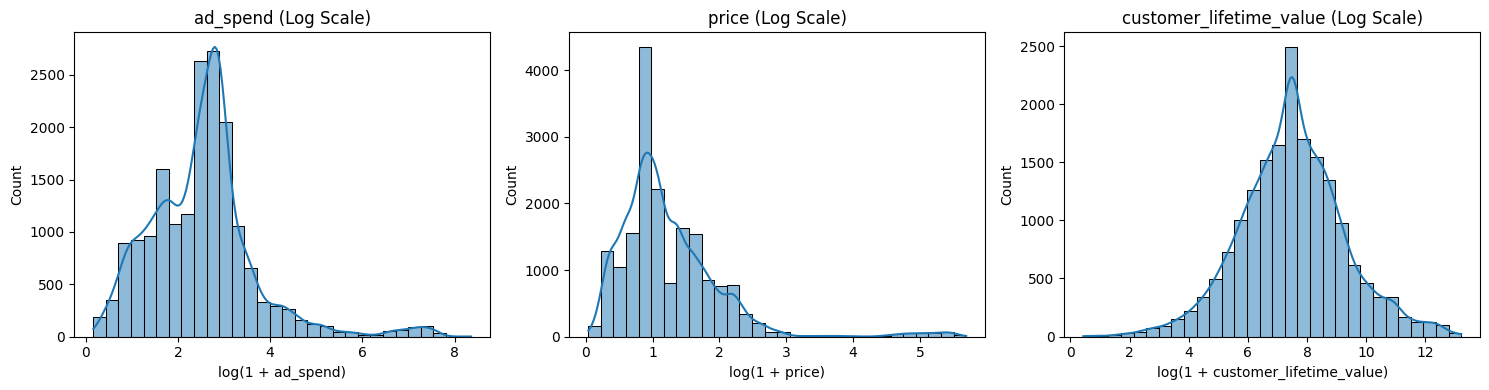

In [66]:

columns = ['ad_spend', 'price', 'customer_lifetime_value']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, col in enumerate(columns):
    sns.histplot(
        np.log1p(df_clean[col]),
        bins=30,
        kde=True,
        ax=axes[i]
    )
    axes[i].set_title(f'{col} (Log Scale)')
    axes[i].set_xlabel(f'log(1 + {col})')

plt.tight_layout()
plt.show()


In [67]:

categorical_cols = [
    'region',
    'channel',
    'product_category',
    'customer_segment'
]

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df_clean[col].value_counts(dropna=False))



--- region ---
region
North      16305
East         374
Norht        248
north        242
NORTH        209
Nort         200
north        199
Central      109
West          77
South         37
Name: count, dtype: int64

--- channel ---
channel
Social Media    4246
Email           3625
Search          3600
Affiliate       2632
TV              1848
Influencer      1806
social Media      55
SocialMedia       50
Social_Media      48
Socail Media      45
social media      45
Name: count, dtype: int64

--- product_category ---
product_category
General       8984
Storage       3775
Seasonal      1878
Stationery    1477
Kitchen       1042
Lighting       844
Name: count, dtype: int64

--- customer_segment ---
customer_segment
Premium     14445
Standard     2764
Budget        791
Name: count, dtype: int64


In [68]:

df_clean['region'] = (
    df_clean['region']
    .str.strip()
    .str.title()
)

df_clean['region'] = df_clean['region'].replace({
    'Norht': 'North',
    'Nort': 'North'
})


In [69]:

df_clean['channel'] = (
    df_clean['channel']
    .str.strip()
    .str.replace('_', ' ', regex=False)
    .str.title()
)

df_clean['channel'] = df_clean['channel'].replace({
    'Socialmedia': 'Social Media',
    'Socail Media': 'Social Media',

    'Tv': 'TV'
})


In [70]:

print("Regions:")
print(df_clean['region'].value_counts())

print("\nChannels:")
print(df_clean['channel'].value_counts())


Regions:
region
North      17403
East         374
Central      109
West          77
South         37
Name: count, dtype: int64

Channels:
channel
Social Media    4489
Email           3625
Search          3600
Affiliate       2632
TV              1848
Influencer      1806
Name: count, dtype: int64


In [71]:

print(df_clean['date'].dtype)
print(df_clean['date'].head())


object
0    05/12/2011 11:31
1    27/04/2011 14:01
2    09/11/2010 15:20
3    03/10/2010 15:24
4    14/10/2011 09:28
Name: date, dtype: object


In [72]:

df_clean['date'] = pd.to_datetime(
    df['date'],
    format='mixed',
    dayfirst=True,
    errors='coerce'
)

print("Invalid dates:", df_clean['date'].isna().sum())
print("Date data type:", df_clean['date'].dtype)


Invalid dates: 0
Date data type: datetime64[ns]


In [73]:

print("Missing dates:", df_clean['date'].isna().sum())

print("Earliest date:", df_clean['date'].min())
print("Latest date:", df_clean['date'].max())


Missing dates: 0
Earliest date: 2009-12-01 00:00:00
Latest date: 2011-12-09 12:19:00


In [74]:

df_clean['year'] = df_clean['date'].dt.year
df_clean['month'] = df_clean['date'].dt.month
df_clean['quarter'] = df_clean['date'].dt.quarter

df_clean[['date', 'year', 'month', 'quarter']].head()


,date,year,month,quarter
0,2011-12-05 11:31:00,2011,12,4
1,2011-04-27 14:01:00,2011,4,2
2,2010-11-09 15:20:00,2010,11,4
3,2010-10-03 15:24:00,2010,10,4
4,2011-10-14 09:28:00,2011,10,4


In [75]:

print("Dataset shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())
print("Negative impressions:", (df_clean['impressions'] < 0).sum())

display(df_clean.head())


Dataset shape: (18000, 20)
Missing values: 0
Duplicate rows: 0
Negative impressions: 0


,id,date,region,channel,product_category,customer_segment,ad_spend,price,discount_rate,market_reach,impressions,click_through_rate,competition_index,seasonality_index,campaign_duration_days,customer_lifetime_value,sales_revenue,year,month,quarter
0,1,2011-12-05 11:31:00,North,Search,General,Standard,9.00,0.75,0.2782,32.0,817.0,0.0010,3.34,1.000000,30.0,816.49,119.767811,2011,12,4
1,2,2011-04-27 14:01:00,North,Social Media,General,Premium,3.35,3.35,0.0912,61.0,2289.0,0.0640,4.44,0.366025,90.0,1723.16,119.404661,2011,4,2
2,3,2010-11-09 15:20:00,North,Affiliate,General,Budget,2.55,2.55,0.1997,461.0,14697.0,0.1508,3.31,0.366025,21.0,1151.74,132.009747,2010,11,4
3,4,2010-10-03 15:24:00,North,Affiliate,Storage,Premium,2.95,2.95,0.4767,744.0,17578.0,0.1965,2.87,-0.366025,90.0,3585.85,154.511756,2010,10,4
4,5,2011-10-14 09:28:00,North,Search,Lighting,Premium,15.00,1.25,0.3536,226.0,6280.0,0.0200,7.40,-0.366025,90.0,502.28,128.059924,2011,10,4


## 4. Exploratory Data Analysis (EDA)

This section examines sales revenue patterns and explores how marketing channels, product categories, customer segments, and campaign characteristics relate to sales performance.

The analysis focuses on:

- Sales revenue distribution and differences across marketing channels.
- Product category and customer segment performance.
- Monthly revenue trends and seasonal patterns.
- Relationships between sales revenue and numerical marketing variables.

The objective is to identify meaningful patterns and potential opportunities for improving marketing performance.

In [76]:

df_clean.groupby('channel')[
    ['ad_spend', 'price', 'customer_lifetime_value']
].agg(['mean', 'median', 'max']).round(2)


ad_spend                 price                 \
                 mean median      max  mean median     max   
channel                                                      
Affiliate       43.90   11.9  4254.50  5.76   1.95  253.25   
Email           44.47   11.9  2006.11  5.82   1.95  295.00   
Influencer      43.64   11.9  2001.96  5.37   1.95  246.10   
Search          44.61   11.9  2008.96  5.05   1.95  295.00   
Social Media    40.36   11.9  2102.40  5.86   1.95  253.65   
TV              40.48   11.9  2021.20  6.06   1.95  252.20   

             customer_lifetime_value                      
                                mean   median        max  
channel                                                   
Affiliate                    9441.65  1781.44  513975.42  
Email                        8900.49  1781.44  522896.88  
Influencer                  11199.79  1784.68  540618.36  
Search                       9701.50  1781.44  543228.10  
Social Media                10467.79  1781.44  533528.50  
TV                          10882.14  1781.44  525714.04

### 4.1 Sales Revenue Distribution

This analysis examines the distribution of sales revenue to understand typical revenue values, variability, and potential skewness.

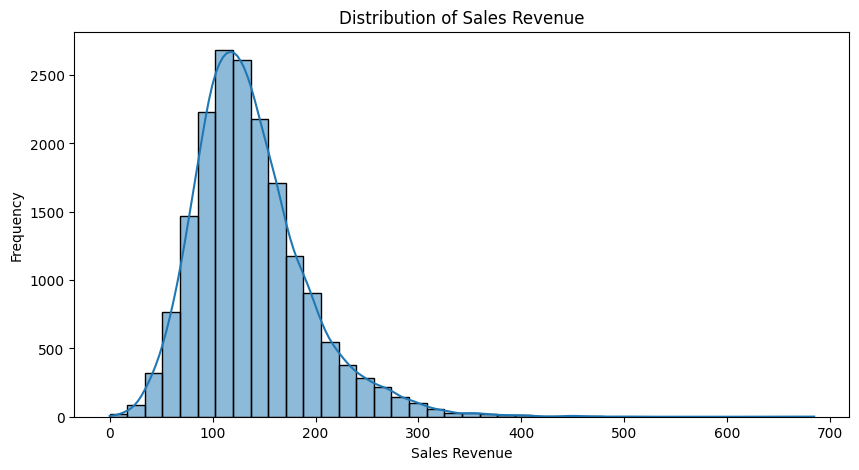

In [77]:

plt.figure(figsize=(10, 5))

sns.histplot(
    df_clean['sales_revenue'],
    bins=40,
    kde=True
)

plt.title('Distribution of Sales Revenue')
plt.xlabel('Sales Revenue')
plt.ylabel('Frequency')
plt.show()




**Key Findings**

- Sales revenue is right-skewed, indicating that most campaign records generate relatively moderate revenue, while a smaller number achieve substantially higher values.
- The average sales revenue is approximately **137.20**, compared with a median of **129.11**.
- Most revenue values are concentrated between approximately **80 and 180**, with a maximum of **684.32**.

**Business Insight**

Sales performance varies across campaign records, with a relatively small number of high-revenue observations pulling the average above the median. Both average and median revenue should be considered when evaluating typical campaign performance.

### 4.2 Sales Revenue by Marketing Channel

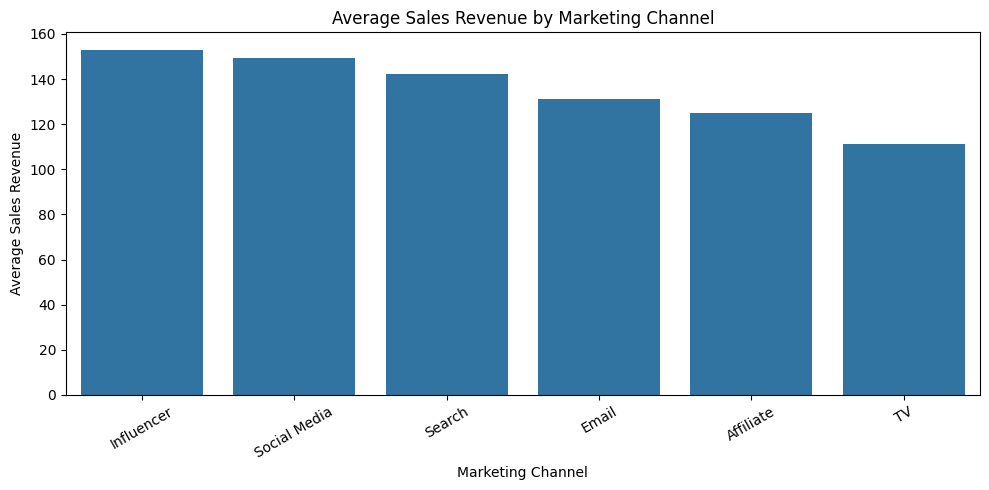

In [78]:

channel_revenue = (
    df_clean.groupby('channel')['sales_revenue']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=channel_revenue.index,
    y=channel_revenue.values
)

plt.title('Average Sales Revenue by Marketing Channel')
plt.xlabel('Marketing Channel')
plt.ylabel('Average Sales Revenue')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()




**Key Findings**

- Influencer marketing generates the highest average sales revenue per campaign record, at approximately **153**.
- Social Media follows closely, with average revenue of approximately **150**.
- Search generates approximately **142** in average revenue.
- TV has the lowest average revenue, at approximately **111**.

**Business Insight**

Influencer marketing and Social Media are associated with stronger average revenue performance, while TV shows comparatively weaker results.

However, average revenue alone does not account for advertising costs or differences in campaign volume. A separate marketing efficiency analysis is therefore necessary before recommending changes to advertising budgets.

In [79]:

channel_performance = df_clean.groupby('channel').agg(
    total_revenue=('sales_revenue', 'sum'),
    total_ad_spend=('ad_spend', 'sum'),
    campaigns=('id', 'count')
)

channel_performance['revenue_to_spend'] = (
    channel_performance['total_revenue'] /
    channel_performance['total_ad_spend']
)

channel_performance = channel_performance.sort_values(
    'revenue_to_spend', ascending=False
)

display(channel_performance.round(2))


,total_revenue,total_ad_spend,campaigns,revenue_to_spend
channel,,,,
Social Media,670616.09,181178.67,4489,3.70
Influencer,276411.79,78807.70,1806,3.51
Search,512284.33,160588.24,3600,3.19
Email,476153.80,161199.36,3625,2.95
Affiliate,328722.00,115549.69,2632,2.84
TV,205500.85,74799.65,1848,2.75


### 4.3 Sales Revenue by Product Category

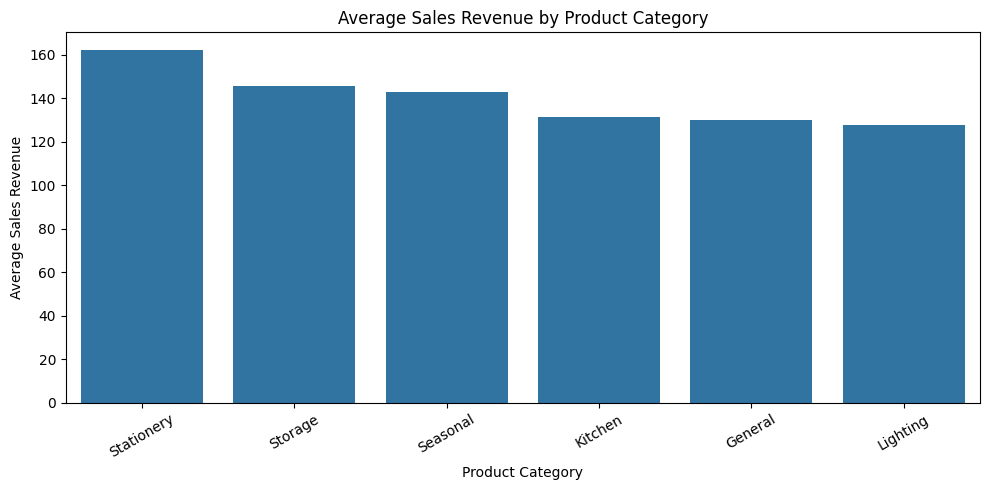

In [80]:

category_revenue = (
    df_clean.groupby('product_category')['sales_revenue']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=category_revenue.index,
    y=category_revenue.values
)

plt.title('Average Sales Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Average Sales Revenue')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()




**Key Findings**

- Stationery generates the highest average sales revenue, at approximately **162** per record.
- Storage and Seasonal products follow, with average revenues of approximately **145** and **143**, respectively.
- Kitchen, General, and Lighting categories show lower average revenue, ranging from approximately **128 to 132**.
- The General category contains more observations, highlighting the importance of distinguishing average performance from total revenue contribution.

**Business Insight**

Stationery demonstrates the strongest average revenue performance among product categories. However, category performance should be evaluated using both average revenue and campaign volume before making product-level marketing decisions.

### 4.4 Sales Revenue by Customer Segment

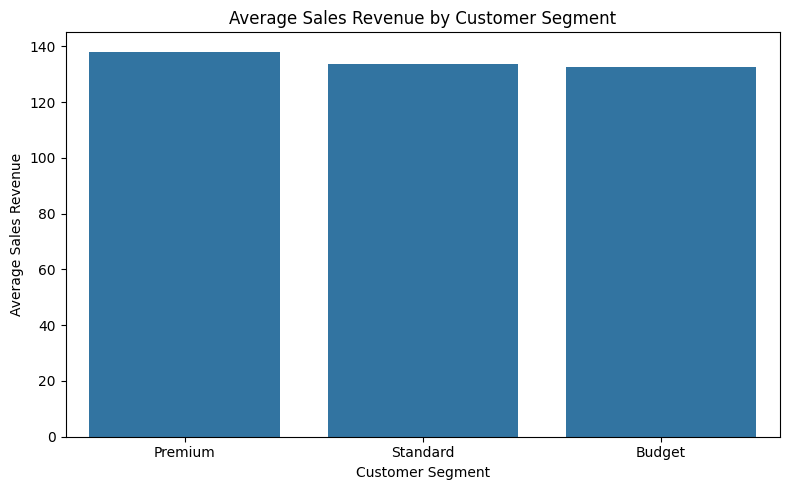

In [81]:

segment_revenue = (
    df_clean.groupby('customer_segment')['sales_revenue']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=segment_revenue.index,
    y=segment_revenue.values
)

plt.title('Average Sales Revenue by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Average Sales Revenue')
plt.tight_layout()
plt.show()


**Key Findings**

- Premium customers generate the highest average sales revenue, at approximately **138**.
- Standard customers generate approximately **134**.
- Budget customers generate approximately **133**.
- Differences in average revenue between the three segments are relatively small.

**Business Insight**

Customer segment alone does not appear to strongly differentiate average sales revenue. Combining customer segments with marketing channels may reveal more meaningful differences in performance.

### 4.5 Monthly Revenue Trends and Seasonality

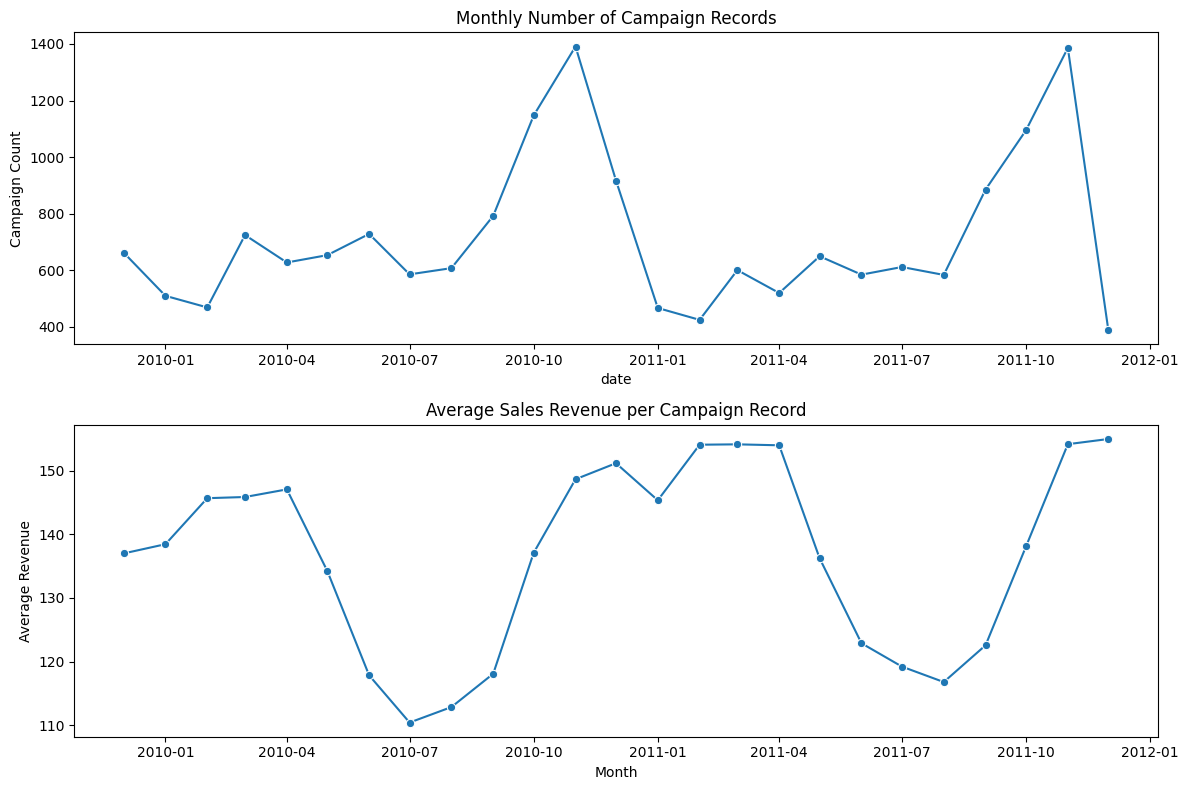

In [82]:

monthly_analysis = (
    df_clean.set_index('date')
    .resample('MS')
    .agg(
        total_revenue=('sales_revenue', 'sum'),
        avg_revenue=('sales_revenue', 'mean'),
        campaign_count=('id', 'count')
    )
)

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

sns.lineplot(
    data=monthly_analysis,
    x=monthly_analysis.index,
    y='campaign_count',
    marker='o',
    ax=axes[0]
)

axes[0].set_title('Monthly Number of Campaign Records')
axes[0].set_ylabel('Campaign Count')

sns.lineplot(
    data=monthly_analysis,
    x=monthly_analysis.index,
    y='avg_revenue',
    marker='o',
    ax=axes[1]
)

axes[1].set_title('Average Sales Revenue per Campaign Record')
axes[1].set_ylabel('Average Revenue')
axes[1].set_xlabel('Month')

plt.tight_layout()
plt.show()




**Key Findings**

- The number of campaign records increases significantly toward the end of the year, particularly in October and November.
- Average sales revenue per campaign record also rises during these months, reaching approximately **150–155**.
- Lower average revenue is observed during the summer months, particularly July and August.
- These patterns appear in both 2010 and 2011, suggesting a recurring seasonal trend.

**Business Insight**

Marketing performance shows seasonal variation, with stronger activity and higher average revenue toward the end of the year.

This suggests that businesses could investigate opportunities to increase marketing activity during high-performing months while examining the factors behind weaker summer performance.

The first and last months of the dataset contain incomplete periods, so their campaign counts should be interpreted cautiously.

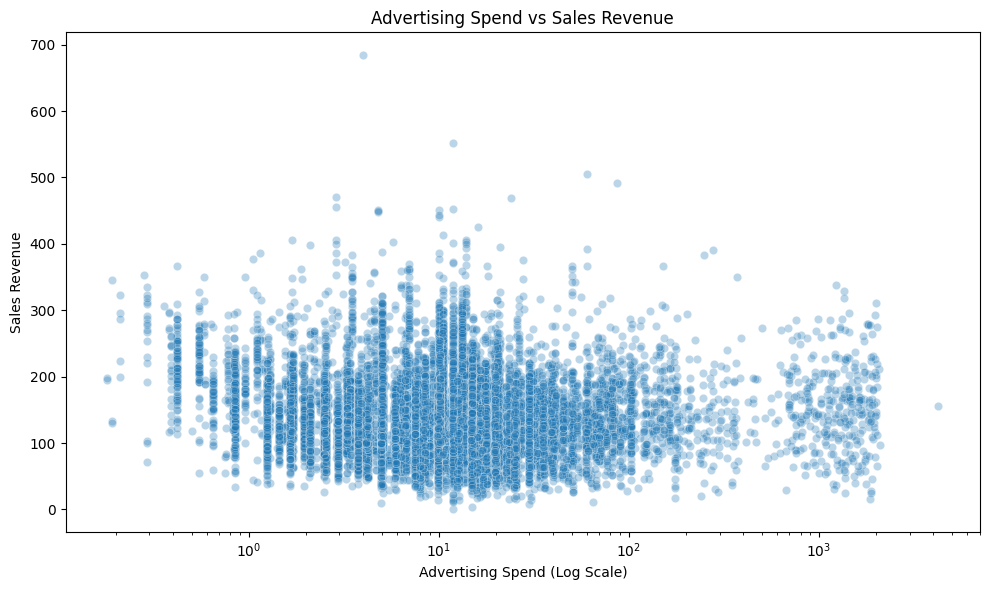

Pearson Correlation: 0.039


In [83]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x='ad_spend',
    y='sales_revenue',
    alpha=0.3
)

plt.xscale('log')

plt.title('Advertising Spend vs Sales Revenue')
plt.xlabel('Advertising Spend (Log Scale)')
plt.ylabel('Sales Revenue')
plt.tight_layout()
plt.show()

correlation = df_clean[
    ['ad_spend', 'sales_revenue']
].corr().iloc[0, 1]

print("Pearson Correlation:", round(correlation, 3))


**Business insight:**

Advertising budget alone is not a strong linear predictor of sales revenue in this dataset.
Other factors, such as marketing channel, product category, customer segment, and seasonality, may help explain revenue differences.
One limitation: Pearson correlation measures linear relationships. A nonlinear relationship could still exist.

### 4.6 Correlation Analysis

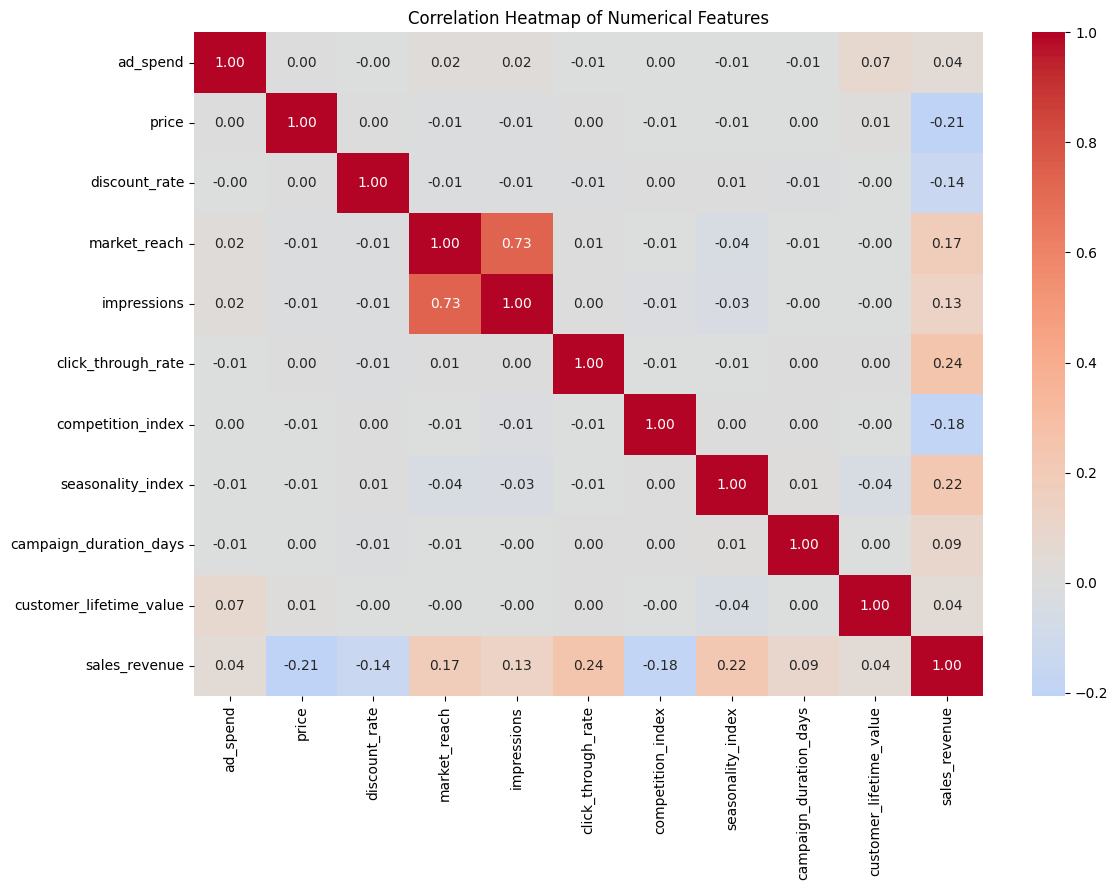

In [84]:

numeric_df = df_clean.select_dtypes(include='number')

# Remove ID and derived date columns
numeric_df = numeric_df.drop(
    columns=['id', 'year', 'month', 'quarter'],
    errors='ignore'
)

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()




**Key Findings**

The correlation analysis examines the strength and direction of linear relationships between numerical marketing variables and sales revenue.

- **Click-through rate (CTR):** Shows the strongest positive correlation with sales revenue among the examined variables (r ≈ 0.24).
- **Seasonality index:** Has a positive correlation with revenue (r ≈ 0.22).
- **Market reach:** Shows a weak positive correlation (r ≈ 0.17).
- **Price:** Shows a negative correlation with revenue (r ≈ -0.21).
- **Competition index:** Shows a weak negative correlation (r ≈ -0.18).
- **Discount rate:** Shows a weak negative correlation (r ≈ -0.14).
- **Advertising spend:** Has a very weak positive correlation (r ≈ 0.04).

**Business Insight**

Customer engagement and seasonal conditions are more strongly associated with sales revenue than advertising spending alone.

However, all observed correlations are relatively weak. These relationships should be interpreted as associations rather than evidence of causation.

### 4.7 Discount Rate and Sales Revenue

,avg_revenue,campaigns
discount_group,,
0-10%,146.29,3864
10-20%,142.11,4571
20-30%,136.04,4516
30-40%,130.14,2447
40-50%,125.79,1486
50-60%,121.06,1116


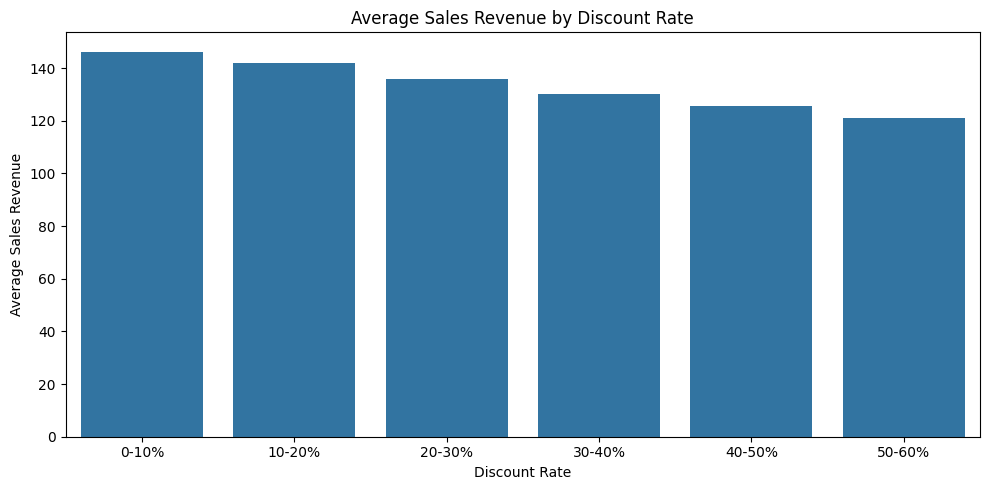

In [85]:

df_clean['discount_group'] = pd.cut(
    df_clean['discount_rate'],
    bins=[0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6],
    labels=['0-10%', '10-20%', '20-30%',
            '30-40%', '40-50%', '50-60%'],
    include_lowest=True
)

discount_analysis = (
    df_clean.groupby('discount_group', observed=True)
    .agg(
        avg_revenue=('sales_revenue', 'mean'),
        campaigns=('id', 'count')
    )
)

display(discount_analysis.round(2))

plt.figure(figsize=(10, 5))

sns.barplot(
    data=discount_analysis.reset_index(),
    x='discount_group',
    y='avg_revenue'
)

plt.title('Average Sales Revenue by Discount Rate')
plt.xlabel('Discount Rate')
plt.ylabel('Average Sales Revenue')
plt.tight_layout()
plt.show()



**Key Findings**

- Average sales revenue generally decreases as the discount rate increases.
- Campaign records with discounts between 0% and 10% show the highest average sales revenue, at approximately **146**.
- Records with higher discount rates show lower average revenue, reaching approximately **121** in the highest discount group.
- This pattern is consistent with the negative correlation observed between discount rate and sales revenue.

**Business Insight**

Higher discounts are associated with lower average sales revenue in this dataset. This suggests that offering larger discounts does not necessarily correspond to stronger revenue performance.

However, this analysis does not establish that discounts cause revenue to decrease. Other factors, such as product category, pricing, and customer segment, may influence the relationship.

### 4.8 Factors Associated with Sales Revenue
This section explores how customer engagement, seasonal conditions, product pricing, and market competition relate to sales revenue.

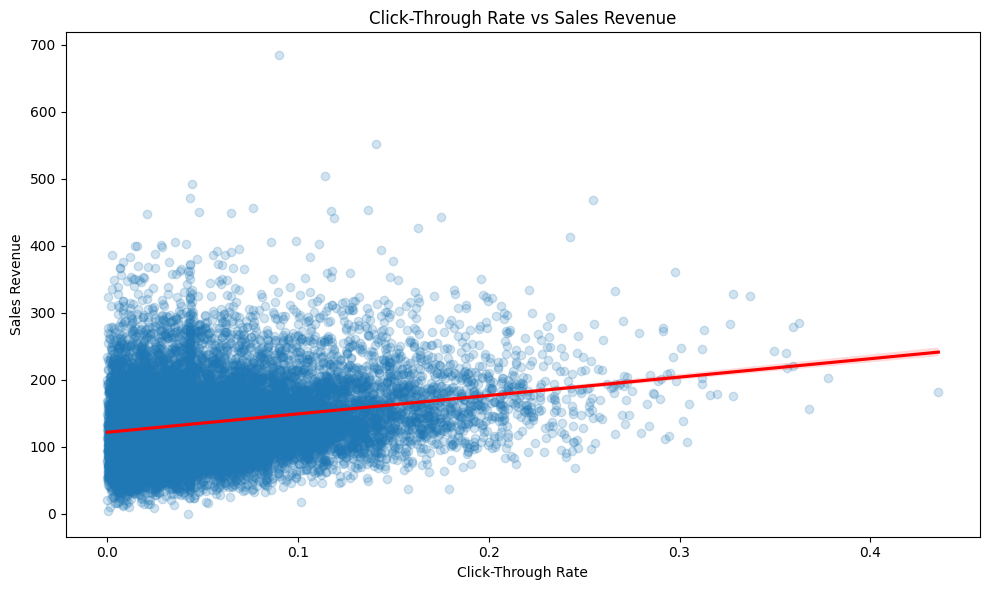

In [86]:

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_clean,
    x='click_through_rate',
    y='sales_revenue',
    scatter_kws={'alpha': 0.2},
    line_kws={'color': 'red'}
)

plt.title('Click-Through Rate vs Sales Revenue')
plt.xlabel('Click-Through Rate')
plt.ylabel('Sales Revenue')
plt.tight_layout()
plt.show()


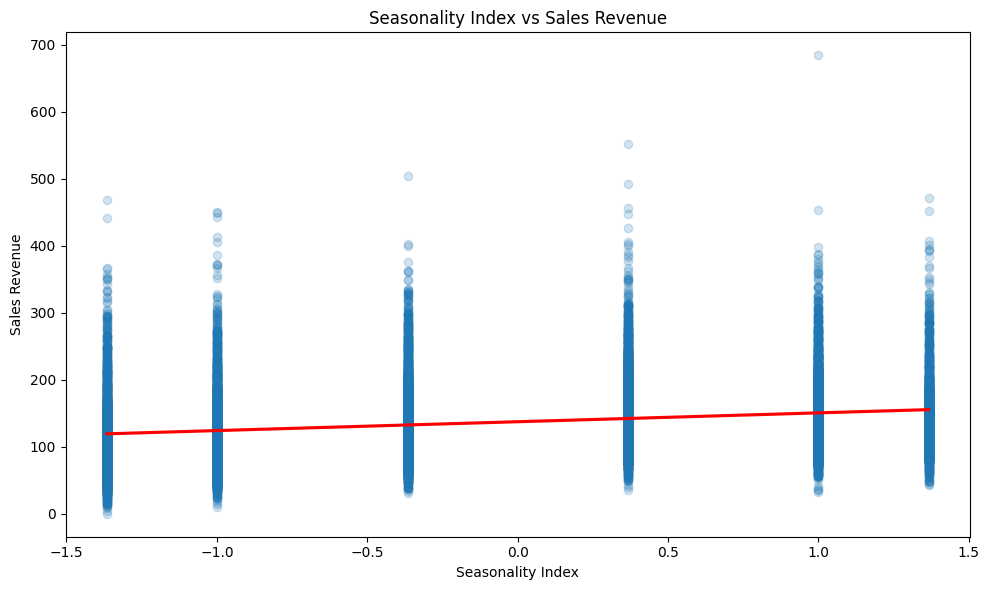

In [87]:

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_clean,
    x='seasonality_index',
    y='sales_revenue',
    scatter_kws={'alpha': 0.2},
    line_kws={'color': 'red'}
)

plt.title('Seasonality Index vs Sales Revenue')
plt.xlabel('Seasonality Index')
plt.ylabel('Sales Revenue')
plt.tight_layout()
plt.show()


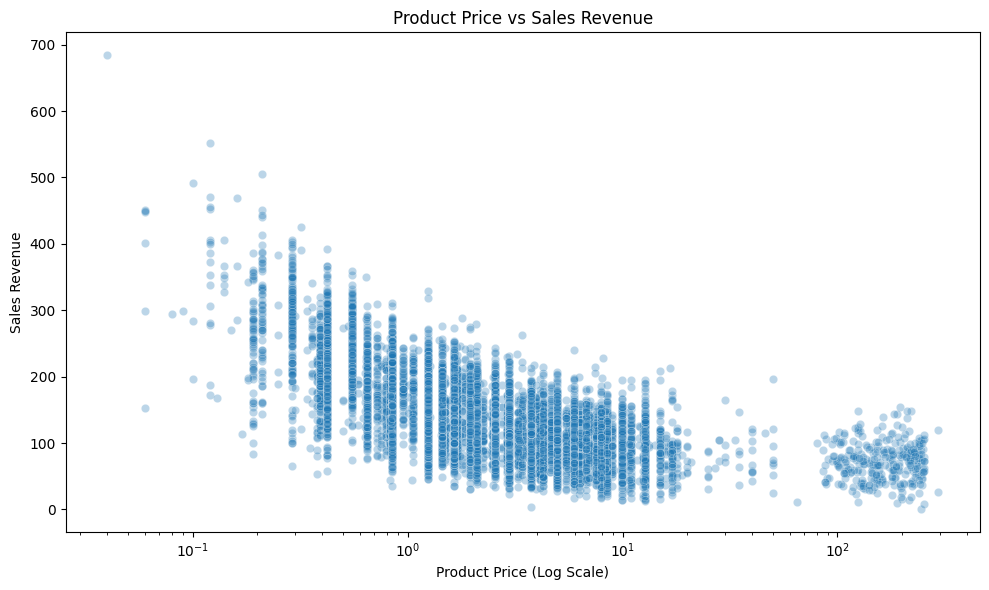

Pearson Correlation: -0.206


In [88]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x='price',
    y='sales_revenue',
    alpha=0.3
)

plt.xscale('log')

plt.title('Product Price vs Sales Revenue')
plt.xlabel('Product Price (Log Scale)')
plt.ylabel('Sales Revenue')
plt.tight_layout()
plt.show()

correlation = df_clean[
    ['price', 'sales_revenue']
].corr().iloc[0, 1]

print("Pearson Correlation:", round(correlation, 3))


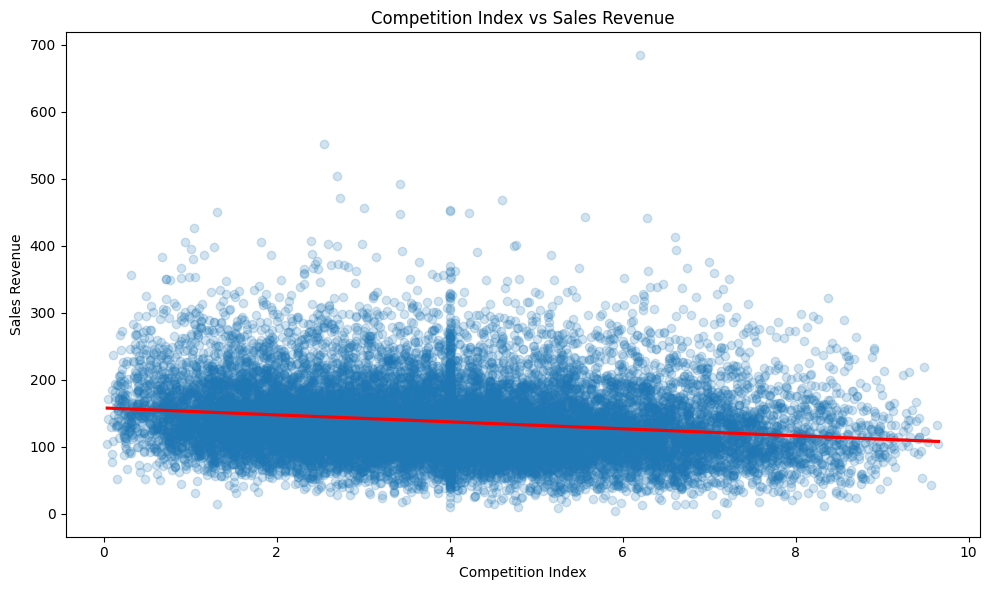

In [89]:

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_clean,
    x='competition_index',
    y='sales_revenue',
    scatter_kws={'alpha': 0.2},
    line_kws={'color': 'red'}
)

plt.title('Competition Index vs Sales Revenue')
plt.xlabel('Competition Index')
plt.ylabel('Sales Revenue')
plt.tight_layout()
plt.show()



**Key Findings**

- **Click-through rate (CTR):** Higher CTR values are associated with higher sales revenue, suggesting that customer engagement is an important indicator of campaign performance.
- **Seasonality index:** Higher seasonality values are associated with higher revenue, supporting the seasonal patterns observed in the monthly analysis.
- **Price:** Higher product prices are associated with slightly lower sales revenue.
- **Competition index:** Higher competition levels are associated with lower sales revenue.

**Business Insight**

Customer engagement and seasonal conditions show positive relationships with revenue, while pricing and competition show negative relationships.

These findings suggest that marketers should evaluate engagement, seasonal demand, pricing, and competitive conditions together when assessing campaign performance.

The relationships are relatively weak and observational, so they should not be interpreted as causal effects.

## 5. Marketing Channel and Customer Segment Analysis

### 5.1 Revenue Performance by Channel and Customer Segment

This analysis examines how marketing channel performance differs across customer segments. Two metrics are considered: average sales revenue and the number of campaign records.

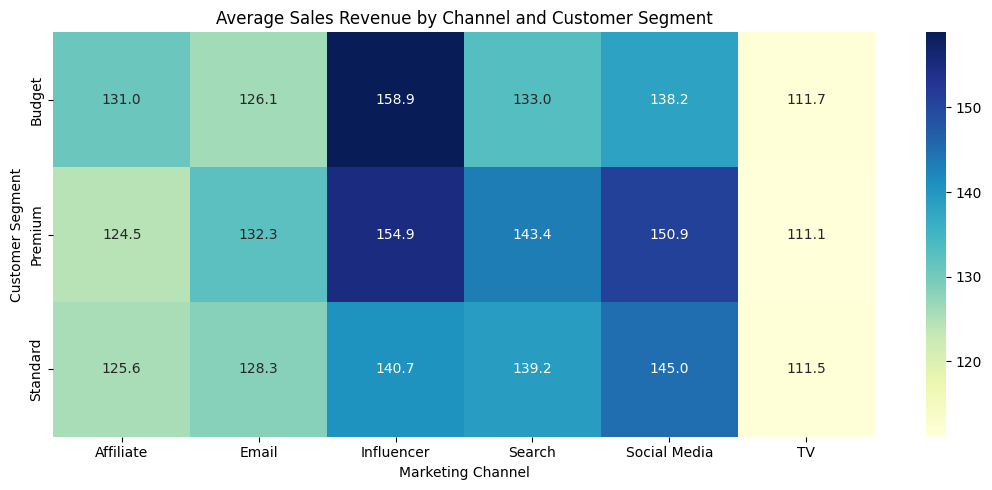

In [90]:

segment_channel = df_clean.pivot_table(
    index='customer_segment',
    columns='channel',
    values='sales_revenue',
    aggfunc='mean'
)

plt.figure(figsize=(11, 5))

sns.heatmap(
    segment_channel,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu'
)

plt.title('Average Sales Revenue by Channel and Customer Segment')
plt.xlabel('Marketing Channel')
plt.ylabel('Customer Segment')
plt.tight_layout()
plt.show()


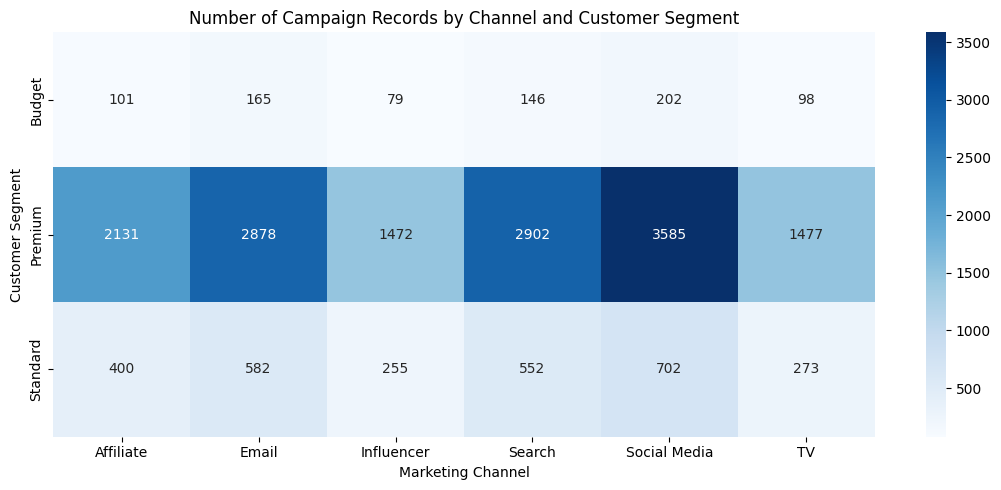

In [91]:

segment_counts = df_clean.pivot_table(
    index='customer_segment',
    columns='channel',
    values='id',
    aggfunc='count',
    fill_value=0
)

plt.figure(figsize=(11, 5))

sns.heatmap(
    segment_counts,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Number of Campaign Records by Channel and Customer Segment')
plt.xlabel('Marketing Channel')
plt.ylabel('Customer Segment')
plt.tight_layout()
plt.show()


In [92]:

df_clean.groupby(
    ['channel', 'customer_segment']
)['sales_revenue'].agg(
    ['count', 'mean', 'sum']
).round(2)


count    mean        sum
channel      customer_segment                          
Affiliate    Budget              101  131.03   13233.53
             Premium            2131  124.46  265234.11
             Standard            400  125.64   50254.36
Email        Budget              165  126.09   20805.04
             Premium            2878  132.27  380682.98
             Standard            582  128.29   74665.79
Influencer   Budget               79  158.86   12550.03
             Premium            1472  154.87  227973.04
             Standard            255  140.74   35888.71
Search       Budget              146  133.03   19423.00
             Premium            2902  143.35  416013.36
             Standard            552  139.22   76847.97
Social Media Budget              202  138.19   27913.40
             Premium            3585  150.89  540947.65
             Standard            702  144.95  101755.03
TV           Budget               98  111.66   10942.82
             Premium            1477  111.11  164110.31
             Standard            273  111.53   30447.71

**Key Findings**

- **Influencer + Budget** generates the highest average sales revenue among the channel–segment combinations, at approximately **158.86**, but is based on only 79 records.
- **Influencer + Premium** also performs strongly, with average revenue of approximately **154.90** across 1,472 records.
- **Social Media + Premium** generates approximately **150.89** in average revenue across 3,585 records.
- TV generally shows lower average revenue across all customer segments.
- Premium customers account for substantially more campaign records than Budget or Standard customers.

**Business Insight**

Influencer marketing achieves particularly high average revenue among Budget customers, while Social Media performs strongly with Premium customers.

However, high average revenue does not necessarily imply high total revenue. Differences in campaign volume must also be considered when evaluating the contribution of each channel–segment combination.

### 5.2 Marketing Efficiency by Channel and Customer Segment

Marketing efficiency is evaluated using the revenue-to-advertising-spend ratio, calculated as:

**Revenue-to-Spend Ratio = Total Sales Revenue / Total Advertising Spend**

This metric measures the amount of recorded sales revenue associated with each unit of advertising expenditure. It does not represent profit or account for other business costs.

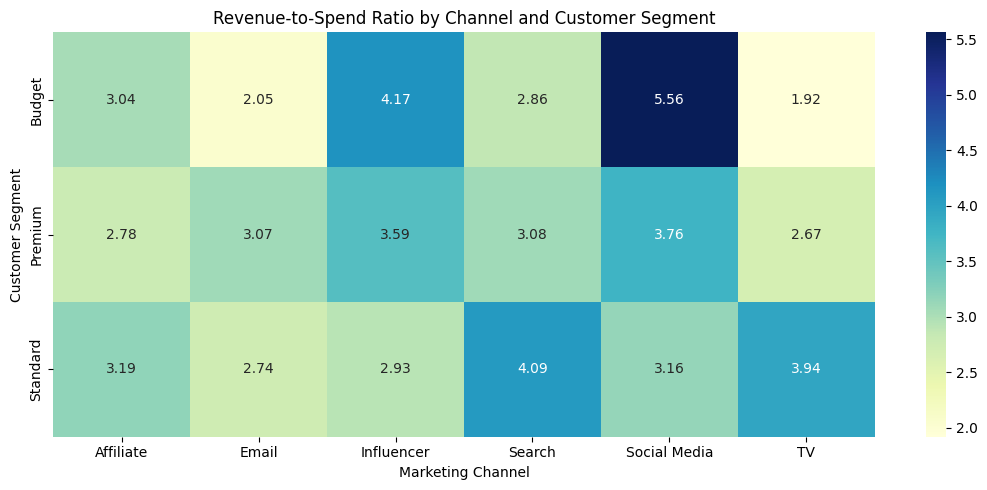

In [93]:

segment_efficiency = df_clean.groupby(
    ['customer_segment', 'channel']
).agg(
    total_revenue=('sales_revenue', 'sum'),
    total_ad_spend=('ad_spend', 'sum'),
    campaigns=('id', 'count')
)

segment_efficiency['revenue_to_spend'] = (
    segment_efficiency['total_revenue'] /
    segment_efficiency['total_ad_spend']
)

efficiency_heatmap = segment_efficiency[
    'revenue_to_spend'
].unstack()

plt.figure(figsize=(11, 5))

sns.heatmap(
    efficiency_heatmap,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu'
)

plt.title('Revenue-to-Spend Ratio by Channel and Customer Segment')
plt.xlabel('Marketing Channel')
plt.ylabel('Customer Segment')
plt.tight_layout()
plt.show()


#### Key Findings

- **Social Media + Budget** has the highest revenue-to-spend ratio in the full dataset, at **5.56**.
- **Influencer + Budget** follows with a ratio of **4.17**, although this combination contains only 79 campaign records.
- **Search + Standard** shows strong efficiency, with a ratio of **4.09**.
- **Social Media + Premium** generates a ratio of **3.76** and contributes substantially more total revenue due to its larger number of campaign records.
- **TV + Budget** has the lowest ratio, at **1.92**.

#### Business Insight

Marketing efficiency varies considerably across customer segments and channels. Social Media performs particularly well among Budget customers, while Search demonstrates strong efficiency among Standard customers.

However, these rankings should be interpreted cautiously because extreme advertising spending values can substantially affect the revenue-to-spend ratio. A sensitivity analysis is conducted in the following section to evaluate the stability of these findings.

### 5.3 Validation of Marketing Efficiency

To better understand the revenue-to-spend results, selected channel–segment combinations are compared using campaign counts, average and median advertising spend, total advertising spend, and total sales revenue.

This comparison helps distinguish combinations that generate high total revenue from those that achieve high revenue relative to advertising expenditure.

In [94]:

validation = df_clean.groupby(
    ['customer_segment', 'channel']
).agg(
    campaigns=('id', 'count'),
    avg_ad_spend=('ad_spend', 'mean'),
    median_ad_spend=('ad_spend', 'median'),
    total_ad_spend=('ad_spend', 'sum'),
    avg_revenue=('sales_revenue', 'mean'),
    total_revenue=('sales_revenue', 'sum')
)

validation['revenue_to_spend'] = (
    validation['total_revenue'] /
    validation['total_ad_spend']
)

display(
    validation.loc[
        [
            ('Budget', 'Social Media'),
            ('Budget', 'Influencer'),
            ('Premium', 'Social Media'),
            ('Standard', 'Search')
        ]
    ].round(2)
)


campaigns  avg_ad_spend  median_ad_spend  \
customer_segment channel                                                  
Budget           Social Media        202         24.84             11.7   
                 Influencer           79         38.07             11.9   
Premium          Social Media       3585         40.15             11.9   
Standard         Search              552         34.04             10.5   

                               total_ad_spend  avg_revenue  total_revenue  \
customer_segment channel                                                    
Budget           Social Media         5017.11       138.19       27913.40   
                 Influencer           3007.86       158.86       12550.03   
Premium          Social Media       143951.09       150.89      540947.65   
Standard         Search              18792.51       139.22       76847.97   

                               revenue_to_spend  
customer_segment channel                         
Budget           Social Media              5.56  
                 Influencer                4.17  
Premium          Social Media              3.76  
Standard         Search                    4.09

#### Key Findings — Marketing Efficiency Validation

- **Social Media + Budget** achieves the highest revenue-to-spend ratio among the selected combinations (**5.56**), with 202 campaign records.
- **Influencer + Budget** generates the highest average revenue (**158.86**), but has only 79 records, making the result less reliable.
- **Social Media + Premium** generates the highest total revenue among the selected combinations (**540,947.65**), supported by 3,585 records.
- **Search + Standard** demonstrates strong efficiency, with a revenue-to-spend ratio of **4.09** across 552 records.

**Conclusion**

Social Media + Budget appears to be the most efficient combination in the full dataset, while Social Media + Premium contributes the greatest total revenue among the selected combinations.

However, the efficiency rankings are sensitive to extreme advertising spending values, as examined in the following analysis.

## 6. Outlier Sensitivity Analysis

### 6.1 Impact of Extreme Advertising Spending

Previous analysis identified unusually high advertising spending values. To investigate their influence on marketing efficiency, a sensitivity analysis was performed.

Two scenarios were compared:

1. **Original dataset:** All 18,000 campaign records, including extreme spending values.
2. **Filtered dataset:** Campaign records with advertising spending above the 99th percentile were temporarily excluded.

The 99th percentile threshold was **1,223.64**, resulting in the temporary exclusion of **180 records (1% of the dataset)**.

Revenue-to-spend ratios were recalculated for each marketing channel and customer segment to assess whether the original efficiency rankings remained stable.

This analysis is intended to test the sensitivity of the results, not to identify the excluded observations as errors.

In [95]:

# Calculate the 99th percentile of advertising spend
threshold = df_clean['ad_spend'].quantile(0.99)

# Create a temporary dataset excluding extreme spending
df_no_extreme = df_clean[
    df_clean['ad_spend'] <= threshold
].copy()

def calculate_efficiency(data):
    result = data.groupby(
        ['customer_segment', 'channel']
    ).agg(
        total_revenue=('sales_revenue', 'sum'),
        total_spend=('ad_spend', 'sum'),
        campaigns=('id', 'count')
    )

    result['ratio'] = (
        result['total_revenue'] / result['total_spend']
    )

    return result

original = calculate_efficiency(df_clean)
without_extreme = calculate_efficiency(df_no_extreme)

comparison = pd.DataFrame({
    'Original Ratio': original['ratio'],
    'Without Extreme Spend': without_extreme['ratio'],
    'Original Campaigns': original['campaigns'],
    'Remaining Campaigns': without_extreme['campaigns']
})

comparison['Ratio Change (%)'] = (
    (comparison['Without Extreme Spend'] /
     comparison['Original Ratio'] - 1) * 100
)

display(comparison.round(2))
print("99th percentile threshold:", round(threshold, 2))
print("Excluded records:", len(df_clean) - len(df_no_extreme))


Original Ratio  Without Extreme Spend  \
customer_segment channel                                               
Budget           Affiliate               3.04                   5.33   
                 Email                   2.05                   5.46   
                 Influencer              4.17                   9.89   
                 Search                  2.86                   4.87   
                 Social Media            5.56                   8.34   
                 TV                      1.92                   2.68   
Premium          Affiliate               2.78                   4.44   
                 Email                   3.07                   4.65   
                 Influencer              3.59                   5.53   
                 Search                  3.08                   4.97   
                 Social Media            3.76                   5.74   
                 TV                      2.67                   4.15   
Standard         Affiliate               3.19                   5.15   
                 Email                   2.74                   5.04   
                 Influencer              2.93                   6.68   
                 Search                  4.09                   6.37   
                 Social Media            3.16                   6.17   
                 TV                      3.94                   4.77   

                               Original Campaigns  Remaining Campaigns  \
customer_segment channel                                                 
Budget           Affiliate                    101                  100   
                 Email                        165                  161   
                 Influencer                    79                   78   
                 Search                       146                  144   
                 Social Media                 202                  201   
                 TV                            98                   97   
Premium          Affiliate                   2131                 2109   
                 Email                       2878                 2851   
                 Influencer                  1472                 1458   
                 Search                      2902                 2868   
                 Social Media                3585                 3555   
                 TV                          1477                 1464   
Standard         Affiliate                    400                  398   
                 Email                        582                  574   
                 Influencer                   255                  251   
                 Search                       552                  547   
                 Social Media                 702                  692   
                 TV                           273                  272   

                               Ratio Change (%)  
customer_segment channel                         
Budget           Affiliate                75.03  
                 Email                   165.91  
                 Influencer              136.99  
                 Search                   70.31  
                 Social Media             49.94  
                 TV                       39.35  
Premium          Affiliate                59.86  
                 Email                    51.24  
                 Influencer               54.07  
                 Search                   61.35  
                 Social Media             52.72  
                 TV                       55.04  
Standard         Affiliate                61.72  
                 Email                    84.00  
                 Influencer              128.18  
                 Search                   55.88  
                 Social Media             95.34  
                 TV                       20.87

99th percentile threshold: 1223.64
Excluded records: 180


### 6.2 Sensitivity Analysis Findings

**Key Findings**

- Removing the highest-spending 1% of records increased the revenue-to-spend ratio across all 18 channel–segment combinations.
- **Influencer + Budget** increased from **4.17 to 9.89**, a change of approximately **137%**.
- **Social Media + Budget** increased from **5.56 to 8.34**, a change of approximately **50%**.
- **Search + Standard** increased from **4.09 to 6.37**, a change of approximately **56%**.
- The efficiency rankings changed after excluding extreme spending values, indicating that the original rankings are sensitive to unusually expensive campaign records.

**Business Insight**

A small proportion of high-spending campaign records has a substantial influence on the overall revenue-to-spend ratios.

The increase in efficiency after excluding these records does not necessarily mean that they represent inefficient or incorrect campaigns. Removing them changes both total advertising spending and total sales revenue.

**Final Decision**

All 18,000 records are retained in the cleaned dataset because there is insufficient evidence that the extreme spending values are data errors.

The original revenue-to-spend ratios remain the primary reported results, while the sensitivity analysis is included to communicate their limitations and uncertainty.

## 7. Business Questions, Findings, and Recommendations

### 7.1 Answers to Business Questions

**Q1. Which marketing channels generate the highest sales revenue?**

Influencer marketing generates the highest average revenue per campaign record (approximately 153), followed by Social Media (150) and Search (142).

However, Social Media generates the highest total revenue (approximately 670,616), reflecting its larger number of campaign records.

**Q2. Which product categories and customer segments perform best?**

Stationery achieves the highest average sales revenue among product categories (approximately 162), followed by Storage (145) and Seasonal products (143).

Premium customers generate the highest average revenue (approximately 138), although the differences between Premium, Standard, and Budget customers are relatively small.

**Q3. How does sales revenue change over time, and are there seasonal patterns?**

Campaign activity and average sales revenue generally increase toward the end of the year, particularly in October and November.

Lower average revenue is observed during parts of the summer, suggesting a recurring seasonal pattern.

**Q4. Which marketing factors are most strongly associated with sales revenue?**

Click-through rate (r ≈ 0.24) and seasonality index (r ≈ 0.22) show the strongest positive correlations among the variables examined.

Price (r ≈ -0.21) and competition index (r ≈ -0.18) show negative correlations.

Advertising spend has a very weak positive correlation with revenue (r ≈ 0.04), indicating little linear association in this dataset.

**Q5. How do discount rates relate to sales revenue?**

Average sales revenue decreases across increasing discount groups, from approximately 146 for discounts between 0% and 10% to approximately 121 in the highest discount group.

The results indicate a negative association between discount rate and sales revenue, but they do not establish that larger discounts cause lower revenue.

**Q6. Which marketing channel and customer segment combinations demonstrate the strongest performance?**

Influencer + Budget generates the highest average revenue among the channel–segment combinations (158.86), although it is based on only 79 campaign records.

Social Media + Premium generates substantially higher total revenue (540,947.65) across 3,585 records, demonstrating the importance of considering campaign volume alongside average performance.

**Q7. Which combinations generate the highest revenue relative to advertising spending?**

Social Media + Budget achieves the highest revenue-to-spend ratio in the full dataset (5.56), followed by Influencer + Budget (4.17) and Search + Standard (4.09).

These ratios represent recorded sales revenue divided by advertising spending, not profit or net return on investment.

**Q8. How do extreme advertising spending values affect marketing efficiency results?**

Excluding the highest-spending 1% of campaign records (180 observations) substantially increases revenue-to-spend ratios and changes some rankings.

For example:
- Influencer + Budget increases from 4.17 to 9.89.
- Social Media + Budget increases from 5.56 to 8.34.
- Search + Standard increases from 4.09 to 6.37.

This demonstrates that marketing efficiency rankings are sensitive to extreme advertising spending values. All original records are retained because the excluded observations have not been identified as errors.

### 7.2 Business Recommendations

Based on the analysis, the following actions are recommended for further investigation:

1. **Evaluate Social Media and Influencer marketing:** These channels show strong revenue performance and may offer opportunities for targeted campaigns.
2. **Test promising channel–segment combinations:** Social Media + Budget and Search + Standard demonstrate relatively strong efficiency, but results should be validated before increasing advertising budgets.
3. **Plan around seasonal demand:** Investigate opportunities during October and November, when campaign activity and average revenue tend to increase.
4. **Monitor customer engagement:** Evaluate CTR alongside revenue, spending, and other campaign metrics.
5. **Review unusually expensive campaigns:** Investigate high-spending records individually before making decisions based on aggregate efficiency ratios.

### 7.3 Analysis Limitations

- The analysis is observational; correlations do not demonstrate causation.
- Missing-value imputation may affect some statistics and efficiency calculations.
- Extreme advertising spending values have a substantial influence on revenue-to-spend ratios.
- The North region and Premium customer segment are overrepresented in the dataset.
- The first and last months are incomplete, limiting direct comparisons.
- Revenue-to-spend ratios do not account for product costs, operating expenses, or profit margins.

### 7.4 Final Conclusion

The analysis highlights differences in marketing performance across channels, product categories, customer segments, and seasonal periods.

While Social Media and Influencer marketing demonstrate relatively strong revenue performance, the results also show that advertising spending alone has little linear association with sales revenue.

Importantly, the sensitivity analysis reveals that extreme spending values can substantially influence marketing efficiency rankings.

These findings provide a foundation for further investigation, campaign testing, and more informed marketing decision-making.

## 8. Exporting the Cleaned Dataset

The cleaned dataset is exported as a CSV file for further analysis and interactive dashboard development in Power BI.

All 18,000 records are preserved, including legitimate extreme values. Temporary analysis variables that are not required for the dashboard are excluded from the exported file.

In [96]:

df_export = df_clean.drop(
    columns=['discount_group'],
    errors='ignore'
).copy()

df_export.to_csv(
    'marketing_campaign_cleaned.csv',
    index=False
)

print("File saved successfully!")
print("Rows:", df_export.shape[0])
print("Columns:", df_export.shape[1])


File saved successfully!
Rows: 18000
Columns: 20
